In [1]:
!pip install yfinance pandas numpy matplotlib scikit-learn tensorflow

/tmp/ipykernel_14182/3320668300.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  btc = yf.download('BTC-USD', start='2015-01-01', end='2026-05-12')
[*********************100%***********************]  1 of 1 completed


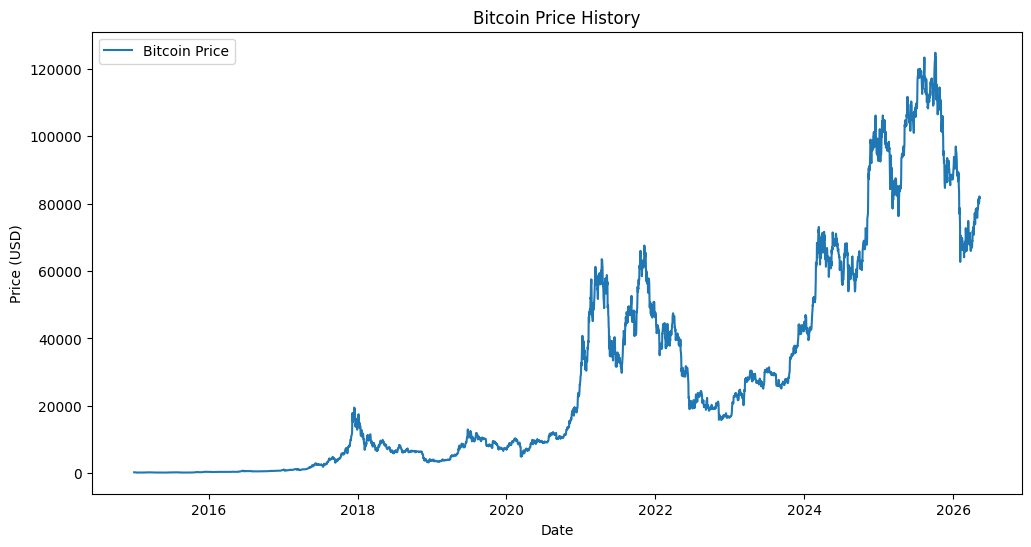

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Fetch Bitcoin historical data
btc = yf.download('BTC-USD', start='2015-01-01', end='2026-05-12')
btc = btc[['Close']]  # Use only closing prices

# Plot the data
plt.figure(figsize=(12, 6))
plt.plot(btc.index, btc['Close'], label='Bitcoin Price')
plt.title('Bitcoin Price History')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [ ]:
# 2. Preprocess Data for LSTM
# LSTMs require data to be scaled and shaped as a 3D array: [samples, timesteps, features].


In [3]:
# Scale the data
scale = MinMaxScaler(feature_range=(0, 1))
scaled_data = scale.fit_transform(btc)

# Create training data
def create_dataset(data, time_step=60):
    X, y = [], []
    for i in range(time_step, len(data)):
        X.append(data[i-time_step:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

time_step = 60
X, y = create_dataset(scaled_data, time_step)

# Split into train and test
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Reshape for LSTM: [samples, timesteps, features]
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (3271, 60, 1)
X_test shape: (818, 60, 1)


In [ ]:
# 3.Build & Train LSTM Model

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - loss: 0.0019 - val_loss: 0.0014
Epoch 2/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 5.2653e-04 - val_loss: 0.0052
Epoch 3/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - loss: 4.6636e-04 - val_loss: 0.0013
Epoch 4/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 5.0415e-04 - val_loss: 0.0012
Epoch 5/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - loss: 4.3564e-04 - val_loss: 0.0043
Epoch 6/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - loss: 3.3915e-04 - val_loss: 0.0018
Epoch 7/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - loss: 3.7075e-04 - val_loss: 0.0019
Epoch 8/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - loss: 3.6414e-04 - val_loss: 0.0017
Epoch 9/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 3.1805e-04 - val_loss: 0.0015
Epoch 10/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - loss: 3.1828e-04 - val_loss: 0.0022
Epoch 11/20
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - loss: 2.7902e-04 - val_loss: 0.001

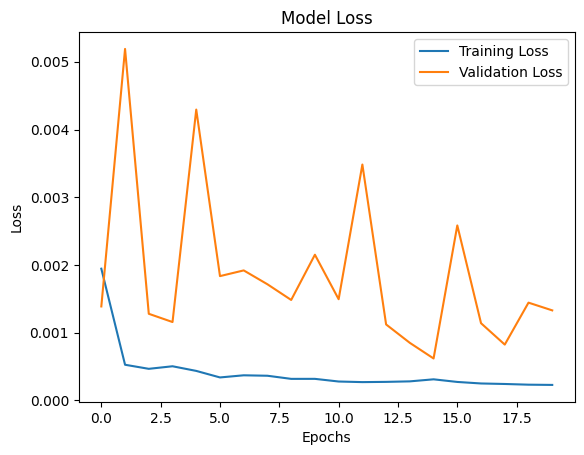

In [4]:
# Build LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(time_step, 1)))
model.add(Dropout(0.2))
model.add(LSTM(50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32,
    verbose=1
)

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# 4. Make Predictions

103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


ValueError: could not broadcast input array from shape (818,1) into shape (758,1)

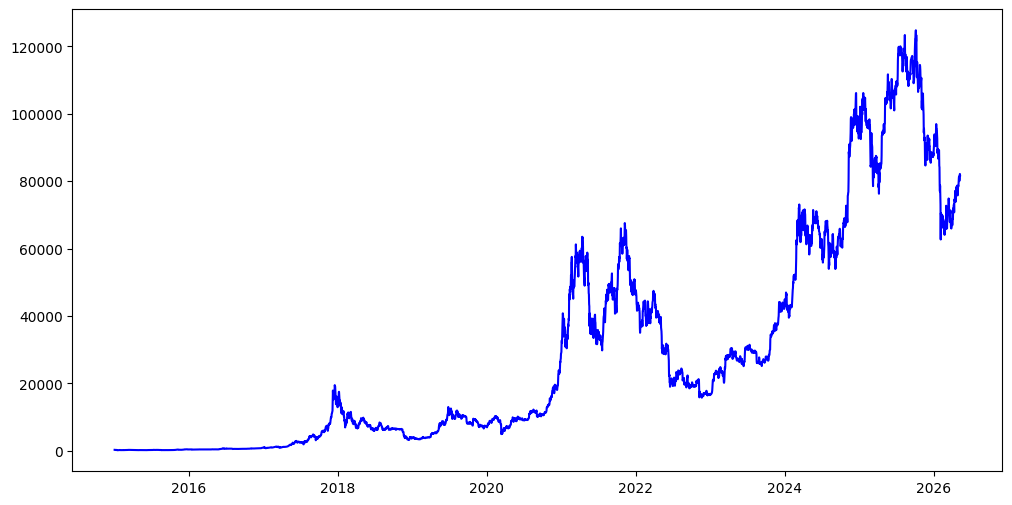

In [5]:
# Predict on test data
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

# Inverse transform to get actual prices
train_predict = scale.inverse_transform(train_predict)
y_train = scale.inverse_transform([y_train])
test_predict = scale.inverse_transform(test_predict)
y_test = scale.inverse_transform([y_test])

# Plot predictions vs actual
plt.figure(figsize=(12, 6))
plt.plot(btc.index, btc['Close'], label='Actual Price', color='blue')

# Shift train predictions for plotting
train_plot = np.empty_like(btc)
train_plot[:, :] = np.nan
train_plot[time_step:len(train_predict)+time_step, :] = train_predict

# Shift test predictions for plotting
test_plot = np.empty_like(btc)
test_plot[:, :] = np.nan
test_plot[len(train_predict)+(time_step*2):len(btc), :] = test_predict

plt.plot(btc.index, train_plot, label='Train Predictions', color='green')
plt.plot(btc.index, test_plot, label='Test Predictions', color='red')
plt.title('Bitcoin Price Prediction')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [ ]:
# 5. Predict Future Prices

In [6]:
def predict_future(model, data, scale, time_step, n_days):
    last_sequence = data[-time_step:]
    predictions = []
    for _ in range(n_days):
        x_input = last_sequence.reshape(1, time_step, 1)
        yhat = model.predict(x_input, verbose=0)
        predictions.append(yhat[0, 0])
        last_sequence = np.append(last_sequence[1:], yhat)
    predictions = scale.inverse_transform(np.array(predictions).reshape(-1, 1))
    return predictions

# Predict next 30 days
future_predictions = predict_future(model, scaled_data, scale, time_step, 30)
print("Next 30 days Bitcoin price predictions:")
print(future_predictions)

Next 30 days Bitcoin price predictions:
[[79239.5  ]
 [78867.81 ]
 [78218.82 ]
 [77420.47 ]
 [76550.234]
 [75655.48 ]
 [74765.65 ]
 [73899.1  ]
 [73066.86 ]
 [72275.08 ]
 [71526.414]
 [70821.06 ]
 [70157.55 ]
 [69533.33 ]
 [68945.18 ]
 [68389.6  ]
 [67863.06 ]
 [67362.19 ]
 [66883.89 ]
 [66425.45 ]
 [65984.53 ]
 [65559.16 ]
 [65147.71 ]
 [64748.902]
 [64361.74 ]
 [63985.406]
 [63619.305]
 [63262.945]
 [62915.965]
 [62578.082]]
